<a href="https://colab.research.google.com/github/pawan-006/Machine-learning/blob/main/Practical_No7_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [ ]:
file = "wireless_signal_kmeans_dataset.csv"

In [ ]:
import pandas as pd

file = "wireless_signal_kmeans_dataset.csv"
data = pd.read_csv(file)

In [ ]:
# Ensure 'file' and 'data' are initialized to prevent NameError
try:
    data
except NameError:
    file = "wireless_signal_kmeans_dataset.csv"
    data = pd.read_csv(file)

if len(data.columns) == 1:
    print("CSV format issue detected. Repairing...")
    data = pd.read_csv(
        file,
        sep=",",
        engine="python"
    )

if len(data.columns) == 1:
    data = data.iloc[:,0].str.split(
        ",",
        expand=True
    )
    data.columns = [
        "RSSI",
        "RSRP",
        "RSRQ",
        "SNR",
        "Latency",
        "Packet_Loss"
    ]

data.columns = data.columns.str.strip()

print("\nDataset Columns:")
print(data.columns)


print("\nDataset Preview:")
print(data.head())


Dataset Columns:
Index(['RSSI', 'RSRP', 'RSRQ', 'SNR', 'Latency', 'Packet_Loss'], dtype='object')

Dataset Preview:
   RSSI   RSRP  RSRQ   SNR  Latency  Packet_Loss
0 -69.9  -99.5 -12.7  10.8     48.1          4.2
1 -89.5 -118.3 -19.0   9.6     81.6          8.8
2 -86.3 -101.6 -20.6   2.2     82.4          6.0
3 -51.3  -82.1  -7.9  20.0     22.7          1.0
4 -55.7  -87.5 -10.2  28.3     17.0          1.8


In [ ]:
data = data.dropna()

for col in data.columns:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data.dropna(inplace=True)

print("\nClean Dataset:")
print(data.head())


Clean Dataset:
   RSSI   RSRP  RSRQ   SNR  Latency  Packet_Loss
0 -69.9  -99.5 -12.7  10.8     48.1          4.2
1 -89.5 -118.3 -19.0   9.6     81.6          8.8
2 -86.3 -101.6 -20.6   2.2     82.4          6.0
3 -51.3  -82.1  -7.9  20.0     22.7          1.0
4 -55.7  -87.5 -10.2  28.3     17.0          1.8


In [ ]:
X = data[
    [
        "RSSI",
        "RSRP",
        "RSRQ",
        "SNR",
        "Latency",
        "Packet_Loss"
    ]
]

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X
)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(

    n_clusters=3,

    random_state=42,

    n_init=10

)

data["Cluster"] = kmeans.fit_predict(
    X_scaled
)

In [ ]:
print("\nCluster Count:")

print(
    data["Cluster"].value_counts()
)



Cluster Count:
Cluster
1    62
2    45
0    43
Name: count, dtype: int64


In [ ]:
cluster_strength = data.groupby(
    "Cluster"
)["RSSI"].mean()

print("\nAverage RSSI:")

print(cluster_strength)


Average RSSI:
Cluster
0   -87.541860
1   -70.001613
2   -55.842222
Name: RSSI, dtype: float64


In [ ]:
sorted_cluster = cluster_strength.sort_values(
    ascending=False
)

quality = {
    sorted_cluster.index[0]: "Good",
    sorted_cluster.index[1]: "Medium",
    sorted_cluster.index[2]: "Poor"
}

data["Signal_Quality"] = data["Cluster"].map(
    quality
)

In [ ]:
print("\nSignal Quality Groups:")

print(
    data[
        [
            "RSSI",
            "Cluster",
            "Signal_Quality"
        ]
    ]
)


Signal Quality Groups:
     RSSI  Cluster Signal_Quality
0   -69.9        1         Medium
1   -89.5        0           Poor
2   -86.3        0           Poor
3   -51.3        2           Good
4   -55.7        2           Good
..    ...      ...            ...
145 -89.1        0           Poor
146 -59.8        2           Good
147 -71.6        1         Medium
148 -74.9        1         Medium
149 -97.9        0           Poor

[150 rows x 3 columns]


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_scaled
)

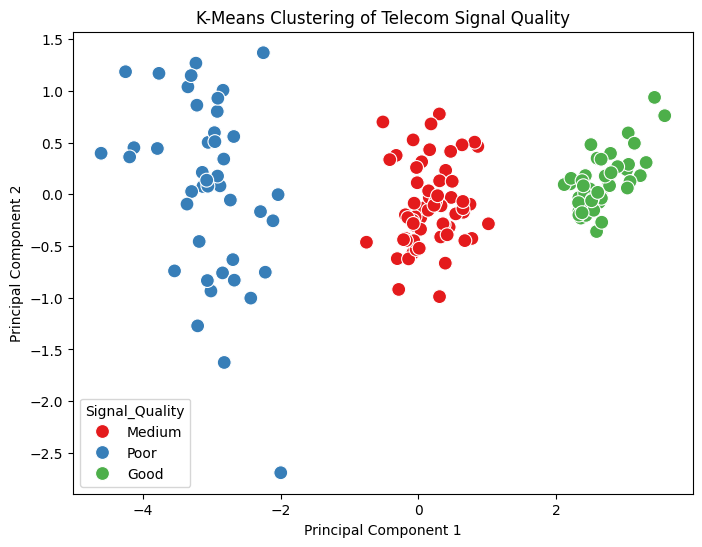

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=data["Signal_Quality"],
    palette="Set1",
    s=100
)

plt.title(
    "K-Means Clustering of Telecom Signal Quality"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.show()

In [ ]:
centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

print("\nCluster Centers:")

print(
    pd.DataFrame(
        centers,
        columns=X.columns
    )
)


Cluster Centers:
        RSSI        RSRP       RSRQ        SNR    Latency  Packet_Loss
0 -87.541860 -109.748837 -17.658140   2.532558  90.616279    11.716279
1 -70.001613  -95.816129 -12.266129  13.143548  44.062903     5.458065
2 -55.842222  -81.251111  -8.266667  23.382222  19.217778     1.471111


In [ ]:
new_signal = [[
    -55,   # RSSI
    -85,   # RSRP
    -9,    # RSRQ
    23,    # SNR
    20,    # Latency
    3      # Packet Loss
]]

In [ ]:

new_scaled = scaler.transform(
    new_signal
)

cluster = kmeans.predict(
    new_scaled
)

print("\nNew Signal Cluster:")

print(cluster[0])

print(
    "Signal Quality:",
    quality[cluster[0]]
)


New Signal Cluster:
2
Signal Quality: Good


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
